In [22]:
!pip install numpy; matplotlib
%pip install gudhi
import numpy as np
import matplotlib.pyplot as plt
import gudhi

/bin/bash: line 1: matplotlib: command not found
Note: you may need to restart the kernel to use updated packages.


In [23]:
def generate_orbit(r, n_points=1000):
    x, y = np.random.uniform(0, 1, size=2)

    orbit = []

    for i in range(n_points):
        x_new = (x + r*y*(1-y)) % 1
        y_new = (y + r*x_new*(1-x_new)) % 1

        x, y = x_new, y_new

        orbit.append([x, y])

    return np.array(orbit)

(1000, 2)


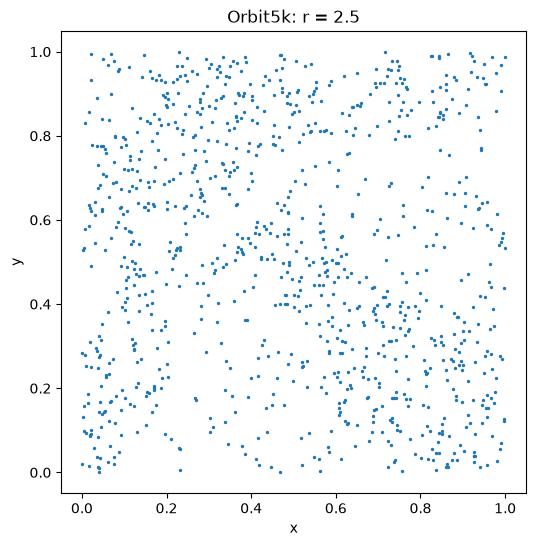

(1000, 2)


In [24]:
orbit = generate_orbit(r=2.5)

print(orbit.shape)

plt.figure(figsize=(6, 6))
plt.scatter(orbit[:, 0], orbit[:, 1], s=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Orbit5k: r = 2.5")
plt.show()
orbit = generate_orbit(r=2.5)

print(orbit.shape)

In [25]:

r_values = [2.5, 3.5, 4.0, 4.1, 4.3]

n_orbits = 1000
n_points = 1000

X = []
y = []

for label, r in enumerate(r_values):

    for i in range(n_orbits):
        orbit = generate_orbit(r, n_points)

        X.append(orbit)
        y.append(label)

X = np.array(X)
y = np.array(y)


In [26]:
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

for label, r in enumerate(r_values):
    print(f"Class {label} (r={r}):", np.sum(y == label))

Dataset shape: (5000, 1000, 2)
Labels shape: (5000,)
Class 0 (r=2.5): 1000
Class 1 (r=3.5): 1000
Class 2 (r=4.0): 1000
Class 3 (r=4.1): 1000
Class 4 (r=4.3): 1000


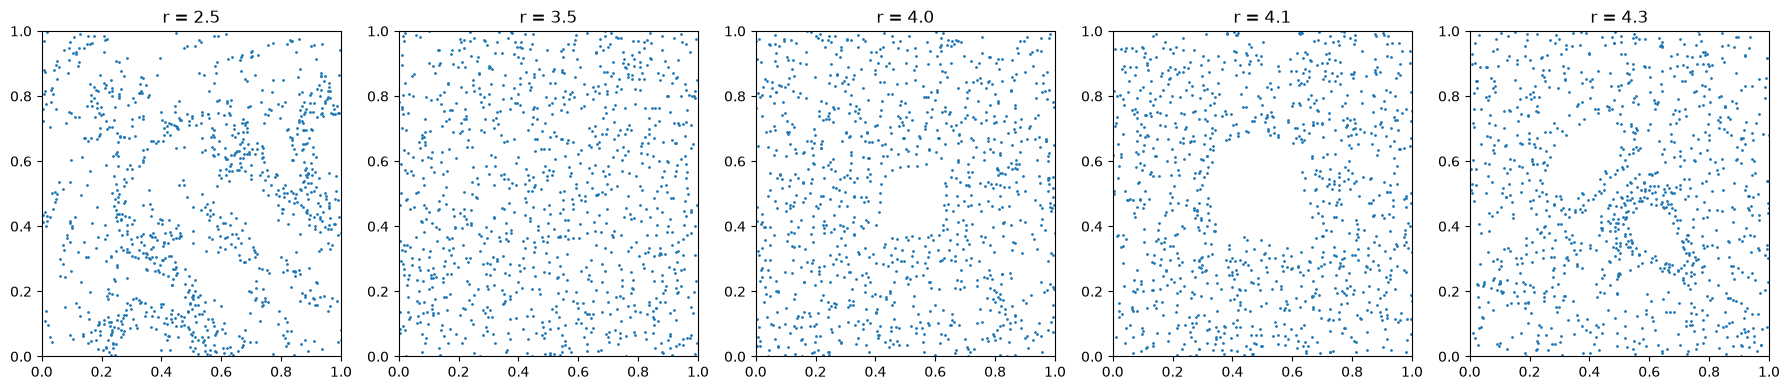

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for label, ax in enumerate(axes):
    ax.scatter(X[label * 1000, :, 0],X[label * 1000, :, 1],s=1)
    ax.set_title(f"r = {r_values[label]}")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [28]:
np.savez_compressed("orbit5k.npz",X=X,y=y,r_values=np.array(r_values))

In [29]:
r = 2.5

# Select one orbit
points = X[0]

print("Parameter:", r)
print("Point cloud shape:", points.shape)
print("First 5 points:\n", points[:5])

Parameter: 2.5
Point cloud shape: (1000, 2)
First 5 points:
 [[0.07945025 0.24507505]
 [0.54198343 0.86566853]
 [0.83269974 0.21394574]
 [0.25313214 0.68658638]
 [0.79109594 0.09974426]]


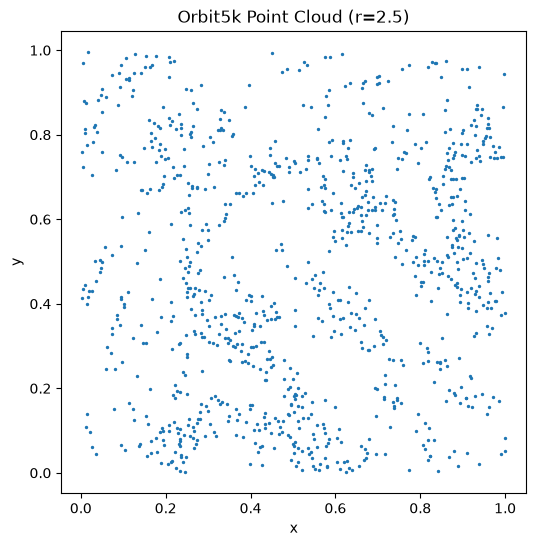

In [30]:
plt.figure(figsize=(6, 6))

plt.scatter(points[:, 0], points[:, 1], s=2)

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Orbit5k Point Cloud (r={r})")
plt.axis("equal")
plt.show()

In [31]:
alpha_complex = gudhi.AlphaComplex(points=points)

print(type(alpha_complex))

<class 'gudhi.delaunay_complex.AlphaComplex'>


In [32]:
simplex_tree = alpha_complex.create_simplex_tree()

print("Number of simplices:", simplex_tree.num_simplices())
print("Number of vertices:", simplex_tree.num_vertices())
print("Dimension:", simplex_tree.dimension())

Number of simplices: 5955
Number of vertices: 1000
Dimension: 2


In [34]:
filtration = list(simplex_tree.get_filtration())

print("Total simplices:", len(filtration))

print("\nFirst 10 simplices:")

for simplex, value in filtration[:10]:
    print(simplex, "->", value)

Total simplices: 5955

First 10 simplices:
[0] -> 0.0
[1] -> 0.0
[2] -> 0.0
[3] -> 0.0
[4] -> 0.0
[5] -> 0.0
[6] -> 0.0
[7] -> 0.0
[8] -> 0.0
[9] -> 0.0


In [35]:
from collections import Counter

dimensions = Counter(
    len(simplex) - 1
    for simplex, value in filtration
)

print(dimensions)

Counter({1: 2977, 2: 1978, 0: 1000})


In [36]:
persistence = simplex_tree.persistence()

print("Number of persistence features:", len(persistence))

D0 = simplex_tree.persistence_intervals_in_dimension(0)
D1 = simplex_tree.persistence_intervals_in_dimension(1)

print("H0 shape:", D0.shape)
print("H1 shape:", D1.shape)

Number of persistence features: 1850
H0 shape: (1000, 2)
H1 shape: (850, 2)


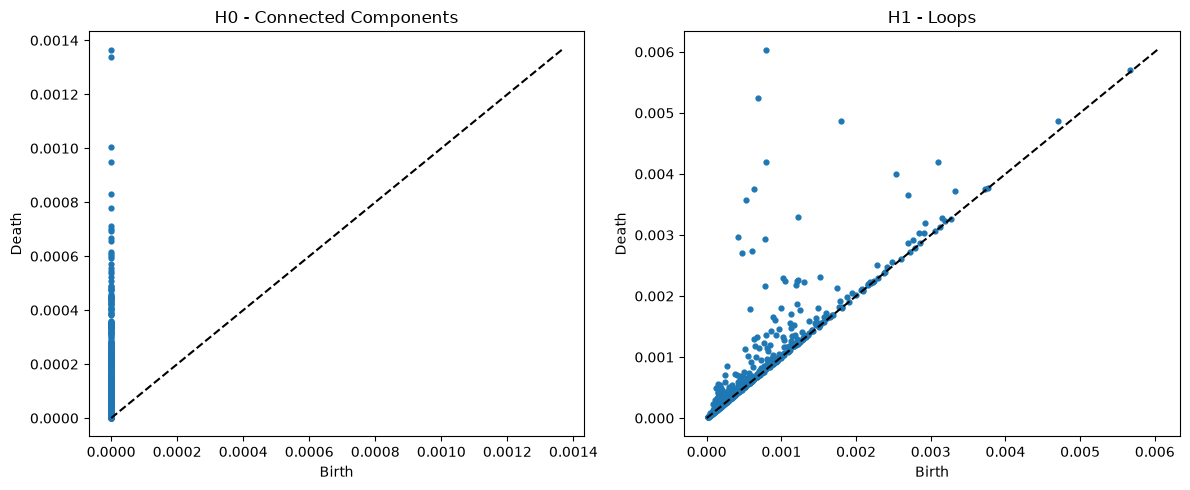

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, D, title in zip(
    axes,
    [D0, D1],
    ["H0 - Connected Components", "H1 - Loops"]
):

    finite = D[np.isfinite(D[:, 1])]

    ax.scatter(finite[:, 0], finite[:, 1], s=12)

    max_val = finite.max() if len(finite) else 1

    ax.plot([0, max_val], [0, max_val], "k--")

    ax.set_xlabel("Birth")
    ax.set_ylabel("Death")
    ax.set_title(title)

plt.tight_layout()
plt.show()